# Lab 10B — Industrial Acoustics: Machine Anomaly Detection (DCASE 2020 Task 2)

**Authored by**: Seetha Parameswaran, BITS Pilani WILP

This is the second of three acoustic-AI labs, and it is a fundamentally different problem from 10A. In health we had labelled examples of every class and trained a classifier. In industry we do not: a production machine runs **normally** for years, and you cannot deliberately break hundreds of machines to collect fault recordings. **There is no labelled abnormal class to learn from.**

So the task changes from classification to **unsupervised anomaly detection**. We train an
**autoencoder on normal-only** audio; it learns to reconstruct the sound of a healthy machine. At test time, a clip the model reconstructs poorly — high reconstruction error — is flagged as anomalous, even though the model has never seen a single fault. Because there is no labelled fault class to train on, the system is scored with **AUC** rather than precision/recall/F1.

## Learning Objectives

By the end of this lab you will be able to:

1. Explain why **unlabelled, rare faults** force anomaly detection instead of classification
2. Convert machine audio into **log-mel feature vectors** for reconstruction
3. Train an **autoencoder on normal-only** data (PyTorch, CPU)
4. Use **reconstruction error** as an anomaly score and set a **threshold from the normal distribution**
5. Evaluate with **AUC** and explain why F1 is inapplicable without labelled faults
6. Recognise when a spectral front-end is appropriate — and when (e.g. bearings) it is not

## Dataset

**DCASE 2020 Challenge Task 2 — Development Dataset** (Koizumi et al.), a repackaging of the MIMII and ToyADMOS machine-sound corpora into a clean per-machine, train/test structure.

This lab uses the **valve** machine type (~1 GB). Other machine types (pump, slider, fan, ToyCar, ToyConveyor) work identically — the method is machine-agnostic.

**Download (Zenodo):**
```
# Search "DCASE 2020 Task 2 development dataset" on zenodo.org, then:
wget -c -O valve.zip "https://zenodo.org/records/3841772/files/dev_data_valve.zip"
unzip -q valve.zip && rm valve.zip
```

**Folder layout** (set `DATA_ROOT` to the folder containing the `valve/` directory):
```
valve/
    train/    normal_id_00_00000000.wav ...     # NORMAL ONLY — training
    test/     normal_id_00_*.wav                # mixed — evaluation
              anomaly_id_00_*.wav               # label is the filename PREFIX
```
The class label lives in the filename prefix (`normal_` / `anomaly_`), not in a folder name.


## 1. Setup


In [1]:
import os, glob
import numpy as np
import librosa
import matplotlib.pyplot as plt
np.random.seed(0)

DATA_ROOT = "/home/seetha/PythonScriptsCourses/PythonScriptsCourses/Audio Analysis/Data/DCASE2020_valve"
MACHINE   = "valve"          # this download is valve

SR      = 16000
N_MELS  = 64
N_FFT   = 1024
HOP     = 512
FRAMES  = 5        # stack 5 consecutive mel frames into one feature vector

train_dir = os.path.join(DATA_ROOT, MACHINE, "train")   # normal ONLY
test_dir  = os.path.join(DATA_ROOT, MACHINE, "test")     # normal + anomaly, label in filename

# TRAIN: all normal (DCASE guarantees train/ contains only normal clips)
normal_files = sorted(glob.glob(os.path.join(train_dir, "*.wav")))

# TEST: split by filename prefix  normal_*  vs  anomaly_*
test_files    = sorted(glob.glob(os.path.join(test_dir, "*.wav")))
test_normal   = [f for f in test_files if os.path.basename(f).startswith("normal_")]
test_abnormal = [f for f in test_files if os.path.basename(f).startswith("anomaly_")]

print(f"train (normal only) : {len(normal_files)}")
print(f"test normal         : {len(test_normal)}")
print(f"test anomaly        : {len(test_abnormal)}")

train (normal only) : 3291
test normal         : 400
test anomaly        : 479


## 2. Front-end note: why log-mel is acceptable here

The framework slide warns that **MFCC destroys bearing fault frequencies** (mel warping
smears the exact BPFO/BPFI peaks). A fan, however, produces *broadband* noise rather
than sharp order-related tones, so a log-mel representation captures the change fine.

For a bearing you would instead use the **Hilbert envelope + FFT**. We keep log-mel here
because it matches the autoencoder-on-spectral-features recipe cleanly.

In [2]:
def file_to_vectors(path):
    y, _ = librosa.load(path, sr=SR, mono=True)
    m = librosa.feature.melspectrogram(y=y, sr=SR, n_fft=N_FFT, hop_length=HOP, n_mels=N_MELS)
    logm = librosa.power_to_db(m, ref=np.max)          # (n_mels, T)
    logm = (logm + 80.0) / 80.0                        # roughly [0,1]
    # sliding window of FRAMES columns -> flattened vectors of length N_MELS*FRAMES
    T = logm.shape[1]
    vecs = [logm[:, t:t+FRAMES].reshape(-1) for t in range(0, T - FRAMES + 1)]
    return np.array(vecs, dtype="float32")

# peek at one file
_v = file_to_vectors(normal_files[0])
print("vectors per clip:", _v.shape[0], "| vector dim:", _v.shape[1])

vectors per clip: 309 | vector dim: 320


## 3. Build the training matrix — normal clips only

The defining constraint of industrial acoustics: the training set contains
**no anomalies at all**. The autoencoder learns to reconstruct *normal* fan sound;
anything it reconstructs poorly is, by definition, unusual.

In [3]:
N_TRAIN_CLIPS = min(200, len(normal_files))   # cap for CPU demo speed

X_train = np.concatenate([file_to_vectors(f) for f in normal_files[:N_TRAIN_CLIPS]], axis=0)
print("X_train:", X_train.shape, "(all NORMAL, from train/)")

INPUT_DIM = X_train.shape[1]

X_train: (61800, 320) (all NORMAL, from train/)


## 4. Dense autoencoder (PyTorch, CPU)

A symmetric bottleneck. It is deliberately small — the goal is a demo that trains
on CPU in a couple of minutes.

In [4]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(0)
device = torch.device("cpu")

class AutoEncoder(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.enc = nn.Sequential(
            nn.Linear(d, 128), nn.ReLU(),
            nn.Linear(128, 32), nn.ReLU(),
            nn.Linear(32, 8),  nn.ReLU(),      # bottleneck
        )
        self.dec = nn.Sequential(
            nn.Linear(8, 32),  nn.ReLU(),
            nn.Linear(32, 128), nn.ReLU(),
            nn.Linear(128, d),
        )
    def forward(self, x):
        return self.dec(self.enc(x))

model = AutoEncoder(INPUT_DIM).to(device)
print(model)

AutoEncoder(
  (enc): Sequential(
    (0): Linear(in_features=320, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=8, bias=True)
    (5): ReLU()
  )
  (dec): Sequential(
    (0): Linear(in_features=8, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=320, bias=True)
  )
)


In [5]:
loader = DataLoader(TensorDataset(torch.from_numpy(X_train)),
                    batch_size=512, shuffle=True)
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
lossf = nn.MSELoss()


EPOCHS = 20
model.train()
for ep in range(EPOCHS):
    total = 0.0
    for (xb,) in loader:
        xb = xb.to(device)
        opt.zero_grad()
        loss = lossf(model(xb), xb)
        loss.backward(); opt.step()
        total += loss.item() * len(xb)
    if (ep + 1) % 5 == 0 or ep == 0:
        print(f"epoch {ep+1:2d}/{EPOCHS}  train MSE {total/len(X_train):.5f}")

epoch  1/20  train MSE 0.05121
epoch  5/20  train MSE 0.00340
epoch 10/20  train MSE 0.00255
epoch 15/20  train MSE 0.00241
epoch 20/20  train MSE 0.00237


## 5. Anomaly score per clip

The score for a clip is the **mean reconstruction error** over its frame-vectors.
Normal clips should score low; anomalies should score high — even though the model
has never seen a single anomaly.

In [6]:
model.eval()
def clip_score(path):
    v = torch.from_numpy(file_to_vectors(path)).to(device)
    with torch.no_grad():
        err = ((model(v) - v) ** 2).mean(dim=1)
    return err.mean().item()

s_normal   = np.array([clip_score(f) for f in test_normal])     # DCASE test/ normal
s_abnormal = np.array([clip_score(f) for f in test_abnormal])   # DCASE test/ anomaly

print(f"normal   scores: mean {s_normal.mean():.4f}  (n={len(s_normal)})")
print(f"abnormal scores: mean {s_abnormal.mean():.4f}  (n={len(s_abnormal)})")


normal   scores: mean 0.0024  (n=400)
abnormal scores: mean 0.0022  (n=479)


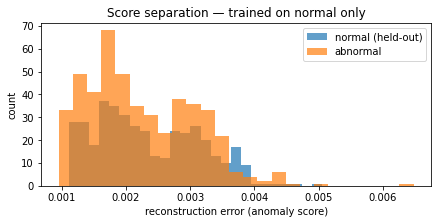

In [7]:
plt.figure(figsize=(7,3))
plt.hist(s_normal,   bins=25, alpha=0.7, label="normal (held-out)")
plt.hist(s_abnormal, bins=25, alpha=0.7, label="abnormal")
plt.xlabel("reconstruction error (anomaly score)"); plt.ylabel("count")
plt.legend(); plt.title("Score separation — trained on normal only"); plt.show()

## 6. Threshold and evaluation

**Threshold** is set from the *normal* score distribution (e.g. mean + 3·std) — because
in deployment that is all you have. **AUC** is the headline metric: it needs no threshold
and no labelled fault class for training, only a handful of known faults to test against.

Precision/recall/F1 are avoided here — they require a labelled abnormal *training* class,
which industrial settings do not provide.

In [8]:
from sklearn.metrics import roc_auc_score

y_true   = np.concatenate([np.zeros(len(s_normal)), np.ones(len(s_abnormal))])
y_scores = np.concatenate([s_normal, s_abnormal])
auc = roc_auc_score(y_true, y_scores)

# threshold from NORMAL distribution only
thr = s_normal.mean() + 3 * s_normal.std()
pred = (y_scores > thr).astype(int)

tp = int(((pred == 1) & (y_true == 1)).sum())
fn = int(((pred == 0) & (y_true == 1)).sum())
fp = int(((pred == 1) & (y_true == 0)).sum())
tn = int(((pred == 0) & (y_true == 0)).sum())

print(f"AUC (threshold-free)          : {auc:.3f}   <-- report THIS")
print(f"Threshold (mean+3sd of normal): {thr:.4f}")
print(f"Detected {tp}/{len(s_abnormal)} anomalies | false alarms {fp}/{len(s_normal)}")
print(f"Confusion: TP={tp} FN={fn} FP={fp} TN={tn}")

AUC (threshold-free)          : 0.457   <-- report THIS
Threshold (mean+3sd of normal): 0.0048
Detected 2/479 anomalies | false alarms 1/400
Confusion: TP=2 FN=477 FP=1 TN=399


## Takeaways

- **Task type:** unsupervised anomaly detection — forced by the **absence of labelled faults**, not   chosen for convenience. This is the defining constraint of industrial acoustic monitoring.
- **Train on normal only.** The autoencoder never sees an anomaly; it simply learns to reconstruct   healthy-machine sound and flags whatever it reconstructs poorly.
- **Threshold from the normal distribution** (e.g. mean + 3·std of normal reconstruction error) —  because in a real deployment that is *all* you have. You cannot tune a threshold on faults you  have never observed.
- **Metric:** AUC (threshold-free). Precision, recall, and F1 require a labelled fault class for  training, which industrial settings do not provide.
- **Front-end caveat:** a log-mel representation suits broadband machine noise like a valve or fan.  For a **bearing**, whose faults appear at exact RPM-derived frequencies (BPFO/BPFI/BSF), mel  warping would smear the very peaks you need — there you would use the Hilbert envelope + FFT instead.
- **Evaluation realism:** the DCASE test set is balanced (~normal ≈ anomaly) so AUC is computable.  A real plant is 99.9% normal; the *training* set being normal-only is the part that mirrors reality,  not the balanced test split.

**Looking across the module (A → B → C):** the feature pipeline barely changes; the **problem definition** does all the work. Health had labels (classify), industry has none (detect anomalies), and the environment has thousands of weakly-labelled classes (stand on a pretrained model). Recognising which situation you are in — before reaching for a model — is the core skill of Acoustic AI.